# 03 — Retreino após o alerta de queda de desempenho (semana 11)

Segundo retreino: disparado pelo alerta de queda de AUC-PR sobre a semana 10, com rótulos até a semana 10 (a semana 9 nunca recebeu rótulos). Pergunta: **o retreino recuperou o desempenho, e onde?** Notebook de análise: só lê o que o pipeline registrou.

In [1]:
import json, urllib.request
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from credit_drift.data import TARGET
from credit_drift.retraining import analysis
from credit_drift.retraining.candidates import features_of
from credit_drift.retraining.window import build_window
from credit_drift.serving.registry import load_champion
from credit_drift.split import REFERENCE_DIR

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
runs = {r["run_week"]: r for r in analysis.retraining_runs()}
run = runs[11]
print({k: run[k] for k in ('run_week', 'through_week', 'trigger', 'chosen', 'versions')})
gates = run['gates']

C:\pos tech\tech-challenge-04\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'run_week': 11, 'through_week': 10, 'trigger': 'performance_drop', 'chosen': 'B', 'versions': {'A': '10', 'B': '11'}}


## 1. Por que retreinar: o que o laço viu

O gatilho vem das métricas que o laço de monitoramento enviou ao Prometheus (PSI máximo por semana) e dos alertas desse run.

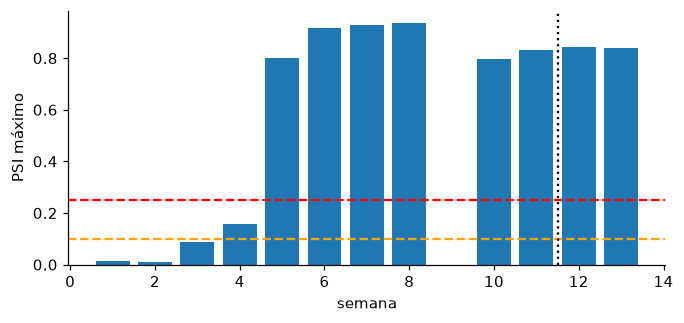

gatilho: performance_drop no run da semana 11; rótulos disponíveis até a semana 10 (atraso de uma semana)


In [2]:
data = json.load(urllib.request.urlopen("http://127.0.0.1:9090/api/v1/query?query=drift_max_psi"))["data"]["result"]
psi = pd.Series({int(r["metric"]["week"]): float(r["value"][1]) for r in data}).sort_index()
fig, ax = plt.subplots(figsize=(7, 3)); ax.bar(psi.index, psi.values, color="tab:blue")
ax.axhline(0.10, color="orange", ls="--"); ax.axhline(0.25, color="red", ls="--")
ax.axvline(run["run_week"] + 0.5, color="k", ls=":"); ax.set_xlabel("semana"); ax.set_ylabel("PSI máximo")
plt.show()
print(f"gatilho: {run['trigger']} no run da semana {run['run_week']}; rótulos disponíveis até a semana {run['through_week']} (atraso de uma semana)")

## 2. Os dois candidatos e o portão

**A** é o campeão atual recalibrado com rótulos recentes; **B** é a mesma receita do campeão reajustada na janela (Referência + semanas rotuladas, com peso maior para as recentes) e recalibrada. O melhor, escolhido **sem** olhar a fatia do portão, vira `challenger`; o portão é um bootstrap pareado numa fatia separada, sem linhas usadas em ajuste ou calibração.

In [3]:
rows = []
for key in ("A", "B"):
    g = gates[key]
    rows.append({"candidato": key, "versão": run["versions"][key], "escolhido": key == run["chosen"],
                 "custo campeão": round(g["cost_champion"], 4), "custo candidato": round(g["cost_challenger"], 4),
                 "ganho de custo (IC 95%)": f"{g['cost_gain']:+.4f} [{g['cost_gain_ci'][0]:+.4f}, {g['cost_gain_ci'][1]:+.4f}]",
                 "AUC-PR dif. (IC 95%)": f"{g['auc_pr_diff']:+.3f} [{g['auc_pr_diff_ci'][0]:+.3f}, {g['auc_pr_diff_ci'][1]:+.3f}]",
                 "passou": g["passed"]})
print("fatia do portão:", gates["A"]["rows"], "linhas,", gates["A"]["defaulters"], "inadimplentes")
pd.DataFrame(rows).set_index("candidato")

fatia do portão: 4000 linhas, 327 inadimplentes


,versão,escolhido,custo campeão,custo candidato,ganho de custo (IC 95%),AUC-PR dif. (IC 95%),passou
candidato,,,,,,,
A,10,False,0.3742,0.3792,"-0.0046 [-0.0190, +0.0093]","+0.000 [+0.000, +0.000]",False
B,11,True,0.3742,0.3705,"+0.0036 [-0.0122, +0.0188]","+0.004 [-0.005, +0.014]",False


O portão exige que o IC de 95% do ganho de custo fique inteiro acima de zero, que o AUC-PR não seja significativamente pior e que o Brier vença o preditor constante.

## 3. Diagrama de confiabilidade na fatia do portão

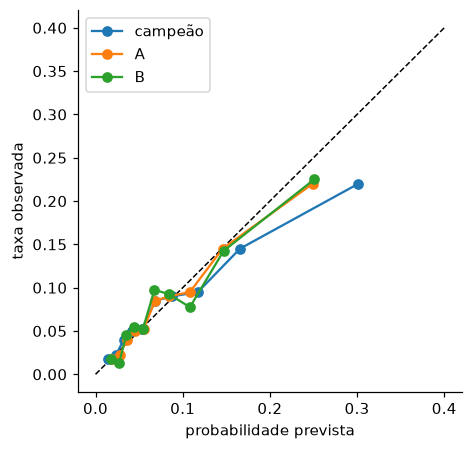

In [4]:
champion = load_champion()
window = build_window(run["through_week"], pd.read_parquet(REFERENCE_DIR / "train.parquet"))
gate = window.gate.reset_index(drop=True)
versions = {"campeão": champion.version, "A": run["versions"]["A"], "B": run["versions"]["B"]}
models = {n: mlflow.sklearn.load_model(f"models:/credit_scoring/{v}") for n, v in versions.items()}
X = features_of(gate)
frame = pd.DataFrame({TARGET: gate[TARGET].to_numpy(), **{n: m.predict_proba(X)[:, 1] for n, m in models.items()}})
fig, ax = plt.subplots(figsize=(4.5, 4.5)); ax.plot([0, 0.4], [0, 0.4], "k--", lw=1)
for name in versions:
    table = analysis.reliability(frame, name); ax.plot(table["predicted"], table["observed"], "o-", label=name)
ax.set_xlabel("probabilidade prevista"); ax.set_ylabel("taxa observada"); ax.legend(); plt.show()

## 4. Os candidatos nas semanas seguintes (semanas 11–13, nunca vistas por estes candidatos)

Os modelos pontuam **as mesmas semanas** que nenhum deles viu no ajuste, então a diferença isola o efeito da intervenção. Como o portão rejeitou o candidato, o campeão seguiu servindo; os candidatos rodam só offline (sombra).

In [5]:
names = {"v1 (campeão)": champion.version, "A": run["versions"]["A"], "B": run["versions"]["B"], "retreino 1 (B)": runs[5]["versions"]["B"]}
scored = analysis.score_weeks(names, [11, 12, 13])
weekly = analysis.per_week(scored, list(names))
weekly.pivot(index="week", columns="model", values="auc_pr").round(3)

model,A,B,retreino 1 (B),v1 (campeão)
week,,,,
11,0.176,0.178,0.171,0.176
12,0.212,0.211,0.204,0.212
13,0.206,0.207,0.206,0.206


In [6]:
base = "v1 (campeão)"
rows = []
for name in names:
    if name == base:
        continue
    g = analysis.gap(scored, base, name)
    rows.append({"modelo": name, **{k: round(v, 4) for k, v in g.items()
                                   if k in ("auc_pr", "auc_pr_low", "auc_pr_high", "cost", "cost_low", "cost_high", "brier")}})
pd.DataFrame(rows).set_index("modelo")

,auc_pr,auc_pr_low,auc_pr_high,brier,cost,cost_low,cost_high
modelo,,,,,,,
A,0.0000,0.0000,0.0000,-0.0004,0.0012,-0.0056,0.0076
B,0.0015,-0.0047,0.0073,-0.0004,0.0045,-0.0033,0.0122
retreino 1 (B),-0.0038,-0.0098,0.0022,0.0002,0.0077,-0.0008,0.0161


As lacunas são `modelo − v1` nas semanas pooladas, com intervalo de bootstrap pareado. Para custo e Brier, valores negativos são melhores.

## 5. Por fatia: dentro e fora do segmento com drift de conceito

O segmento injetado (idade ≤ 45 e renda ≤ mediana do treino) é verdade do simulador, usado só aqui, offline.

In [7]:
rows = []
for label, mask in (("dentro do segmento", scored["in_segment"]), ("fora do segmento", ~scored["in_segment"])):
    part = scored[mask]
    for name in names:
        rows.append({"grupo": label, "modelo": name, "linhas": len(part), "AUC-PR": round(analysis.metrics(part, name)["auc_pr"], 3)})
pd.DataFrame(rows).pivot(index="grupo", columns="modelo", values="AUC-PR")

modelo,A,B,retreino 1 (B),v1 (campeão)
grupo,,,,
dentro do segmento,0.178,0.184,0.17,0.178
fora do segmento,0.210,0.208,0.21,0.210


**Leitura.** O candidato retreinado (B) ficou estatisticamente igual ao v1 nas semanas 11–13: AUC-PR +0,0015 (IC 95% −0,005 a +0,007), custo +0,005 (IC que inclui zero). Dentro do segmento com drift de conceito o AUC-PR sobe de 0,178 para 0,184, um sinal na direção esperada mas pequeno demais para distinguir do ruído; fora do segmento não muda. A recalibração (A) não altera o AUC-PR, como previsto: o ranking continua errado. O portão rejeitou os dois. Com só duas semanas rotuladas do regime novo (8 e 10), das quais 70% ficam reservadas para calibrar e testar, não há evidência para trocar de modelo; recuperar o desempenho pede mais semanas rotuladas. O retreino 1 (B, v9) também ficou ligeiramente pior que o v1 (AUC-PR −0,004, IC que inclui zero).